 # Integrated TFIM Experiment Report & Comparison



 This notebook reads the tutorial-aligned DMRG/MPS, VQE, and `limit_search.py` outputs from `results/tutorial_faithful/`, generating integrated comparison figures and summary tables. It performs post-processing only; run `01_DMRG_MPS_Stress_Tests.ipynb` and `02_VQE_TFIM_Stress_Tests.ipynb` first.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "tutorial_faithful"
expected = [
    "dmrg_environment_record.json",
    "vqe_environment_record.json",
    "dmrg_runs.csv",
    "vqe_runs.csv",
]
status = {name: (RESULTS / name).exists() for name in expected}
status


{'dmrg_environment_record.json': True,
 'vqe_environment_record.json': True,
 'dmrg_runs.csv': True,
 'vqe_runs.csv': True}

 ## 1. Run-table audit



 Counts completed, skipped, interrupted, and errored cases across both notebooks.

In [2]:
dmrg_path = RESULTS / "dmrg_runs.csv"
vqe_path = RESULTS / "vqe_runs.csv"
dmrg = pd.read_csv(dmrg_path) if dmrg_path.exists() else pd.DataFrame()
vqe = pd.read_csv(vqe_path) if vqe_path.exists() else pd.DataFrame()

def status_counts(frame, label):
    if frame.empty:
        return {"dataset": label, "rows": 0, "status_counts": "no file yet"}
    return {
        "dataset": label,
        "rows": len(frame),
        "status_counts": frame.status.value_counts(dropna=False).to_dict(),
    }

status_counts(dmrg, "DMRG"), status_counts(vqe, "VQE")


({'dataset': 'DMRG', 'rows': 58, 'status_counts': {'COMPLETED': 58}},
 {'dataset': 'VQE', 'rows': 81, 'status_counts': {'COMPLETED': 81}})

 ## 2. Method comparison (DMRG/MPS vs. VQE/Statevector)



 Both DMRG/MPS and VQE evaluate the exact same spin-$1/2$ antiferromagnetic TFIM Hamiltonian $H = +J\sum S_i^z S_{i+1}^z - Jg\sum S_i^x$ (`+J/4` $ZZ$ coupling, `-(Jg/2)` $X$ field). DMRG scales polynomially in bond dimension $\chi$ and linearly in $L$, whereas statevector VQE scales exponentially as $O(2^L)$ in memory and runtime.

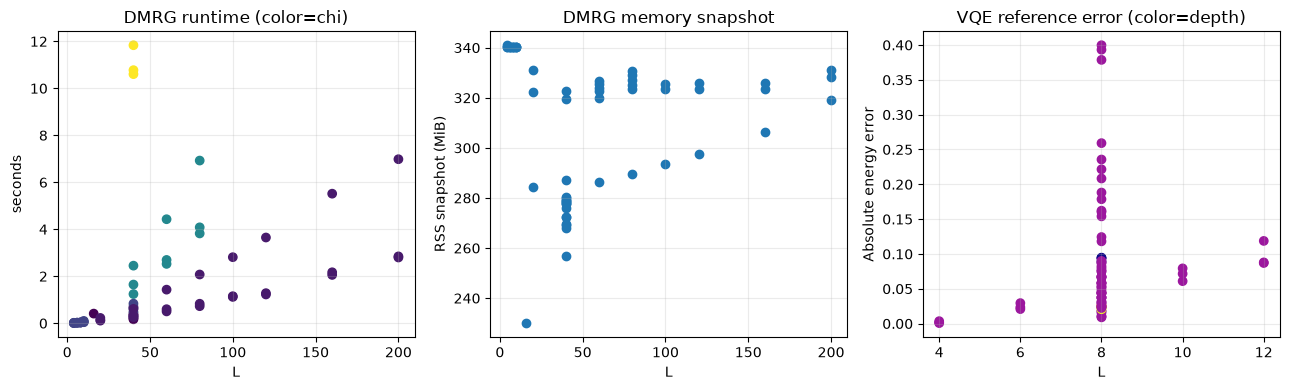

In [3]:
dmrg_done = dmrg[dmrg.status == "COMPLETED"].copy() if not dmrg.empty else pd.DataFrame()
vqe_done = vqe[vqe.status == "COMPLETED"].copy() if not vqe.empty else pd.DataFrame()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
if not dmrg_done.empty:
    axes[0].scatter(dmrg_done.L, dmrg_done.elapsed_seconds, c=dmrg_done.chi, cmap="viridis")
    axes[1].scatter(dmrg_done.L, dmrg_done.rss_after_mib)
if not vqe_done.empty:
    axes[2].scatter(vqe_done.L, vqe_done.absolute_error, c=vqe_done.layers, cmap="plasma")
axes[0].set(xlabel="L", ylabel="seconds", title="DMRG runtime (color=chi)")
axes[1].set(xlabel="L", ylabel="RSS snapshot (MiB)", title="DMRG memory snapshot")
axes[2].set(xlabel="L", ylabel="Absolute energy error", title="VQE reference error (color=depth)")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / "method_comparison_summary.png", dpi=180)
plt.show()


 ## 3. Evidence table



 Summarizes completed runs, median wall times, and post-run RSS snapshots per chain length $L$. Note that post-run RSS snapshots are not peak memory; consult Section 5 (`limit_search.py`) for sampled peak RSS.

In [4]:
summary_rows = []
if not dmrg_done.empty:
    for L, group in dmrg_done.groupby("L"):
        summary_rows.append({
            "method": "DMRG/MPS", "L": int(L), "runs": len(group),
            "median_seconds": group.elapsed_seconds.median(),
            "max_RSS_snapshot_MiB": group.rss_after_mib.max(),
            "accuracy_measure": "See chi/exact tables",
        })
if not vqe_done.empty:
    for L, group in vqe_done.groupby("L"):
        summary_rows.append({
            "method": "VQE", "L": int(L), "runs": len(group),
            "median_seconds": group.elapsed_seconds.median(),
            "max_RSS_snapshot_MiB": group.rss_after_mib.max(),
            "accuracy_measure": f"median |dE| = {group.absolute_error.median():.5f}",
        })
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS / "lab_report_summary.csv", index=False)
summary


,method,L,runs,median_seconds,max_RSS_snapshot_MiB,accuracy_measure
0,DMRG/MPS,4,3,0.008764,341.003906,See chi/exact tables
1,DMRG/MPS,6,3,0.023058,340.402344,See chi/exact tables
2,DMRG/MPS,8,3,0.032461,340.402344,See chi/exact tables
3,DMRG/MPS,10,3,0.054215,340.402344,See chi/exact tables
4,DMRG/MPS,16,1,0.410539,230.074219,See chi/exact tables
5,DMRG/MPS,20,3,0.138022,331.195312,See chi/exact tables
6,DMRG/MPS,40,18,0.623516,322.542969,See chi/exact tables
7,DMRG/MPS,60,6,1.978356,326.542969,See chi/exact tables
8,DMRG/MPS,80,6,2.948860,330.679688,See chi/exact tables
9,DMRG/MPS,100,3,1.151774,325.421875,See chi/exact tables


 ## 4. Resource-frontier evidence (`limit_search.py`)



 Reads the single-case-at-a-time frontier logs (`dmrg_limit_search.csv` and `vqe_limit_search.csv`) with $0.2\text{ s}$ RSS and available-RAM sampling. Protective preflight skips (`SKIPPED_MEMORY_RESERVE`) and configured caps (`TIME_BUDGET_STOPPED`) represent safe operational guardrails rather than solver crashes.

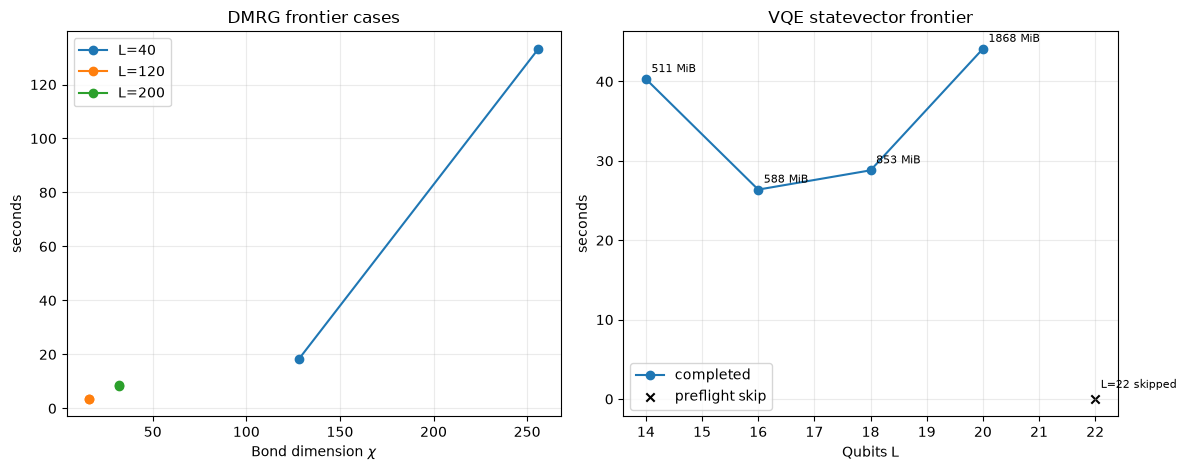

,method,L,chi,status,elapsed_seconds,steps_completed,rss_peak_sampled_mib,minimum_available_gib_sampled,working_set_estimate_gib_heuristic
0,DMRG/MPS,120,16.0,COMPLETED,3.472074,NaN,179.949219,3.854877,NaN
1,DMRG/MPS,200,32.0,COMPLETED,8.138770,NaN,207.703125,3.779942,NaN
2,DMRG/MPS,120,16.0,COMPLETED,3.486761,NaN,179.449219,3.651627,NaN
3,DMRG/MPS,200,32.0,COMPLETED,8.511093,NaN,209.035156,3.791840,NaN
4,DMRG/MPS,40,128.0,COMPLETED,18.214978,NaN,211.144531,3.940403,NaN
5,DMRG/MPS,40,256.0,COMPLETED,133.215926,NaN,332.882812,3.848225,NaN
6,VQE/statevector,14,NaN,COMPLETED,40.306417,100.0,510.679688,3.463650,0.03125
7,VQE/statevector,16,NaN,COMPLETED,26.376879,50.0,587.507812,3.830276,0.12500
8,VQE/statevector,18,NaN,COMPLETED,28.805378,30.0,853.046875,3.482697,0.50000
9,VQE/statevector,20,NaN,COMPLETED,44.107672,15.0,1868.425781,2.560917,2.00000


In [5]:
limit_dir = RESULTS / "limit_search"
dmrg_limit_path = limit_dir / "dmrg_limit_search.csv"
vqe_limit_path = limit_dir / "vqe_limit_search.csv"
dmrg_limit = pd.read_csv(dmrg_limit_path) if dmrg_limit_path.exists() else pd.DataFrame()
vqe_limit = pd.read_csv(vqe_limit_path) if vqe_limit_path.exists() else pd.DataFrame()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
if not dmrg_limit.empty:
    done = dmrg_limit[(dmrg_limit.status == "COMPLETED") & (dmrg_limit.g == 0.5)]
    if done.empty:
        done = dmrg_limit[dmrg_limit.status == "COMPLETED"]
    for L, group in done.groupby("L"):
        group = group.sort_values("chi")
        axes[0].plot(group.chi, group.elapsed_seconds, "o-", label=f"L={int(L)}")
    skipped = dmrg_limit[dmrg_limit.status.str.startswith("SKIPPED", na=False)]
    for _, row in skipped.iterrows():
        axes[0].annotate(
            f"L={int(row.L)}, chi={int(row.chi)}: preflight skip",
            (row.chi, 0), xytext=(4, 8), textcoords="offset points", fontsize=8,
        )
axes[0].set(xlabel=r"Bond dimension $\chi$", ylabel="seconds", title="DMRG frontier cases")
axes[0].grid(alpha=0.25)
if axes[0].get_legend_handles_labels()[0]:
    axes[0].legend()

if not vqe_limit.empty:
    done = vqe_limit[vqe_limit.status.isin(["COMPLETED", "TIME_BUDGET_STOPPED"])]
    for st, marker, label in [("COMPLETED", "o", "completed"), ("TIME_BUDGET_STOPPED", "^", "time-budget stop")]:
        group = done[done.status == st].sort_values("L")
        if not group.empty:
            axes[1].plot(group.L, group.elapsed_seconds, marker=marker, linestyle="-", label=label)
            for _, row in group.iterrows():
                if pd.notna(row.get("rss_peak_sampled_mib")):
                    axes[1].annotate(
                        f"{float(row.rss_peak_sampled_mib):.0f} MiB",
                        (row.L, row.elapsed_seconds), xytext=(4, 5),
                        textcoords="offset points", fontsize=8,
                    )
    skipped = vqe_limit[vqe_limit.status.str.startswith("SKIPPED", na=False)]
    for idx, (_, row) in enumerate(skipped.iterrows()):
        axes[1].scatter([row.L], [0], marker="x", color="black",
                        label="preflight skip" if idx == 0 else None)
        axes[1].annotate(f"L={int(row.L)} skipped", (row.L, 0),
                         xytext=(4, 8), textcoords="offset points", fontsize=8)
axes[1].set(xlabel="Qubits L", ylabel="seconds", title="VQE statevector frontier")
axes[1].grid(alpha=0.25)
if axes[1].get_legend_handles_labels()[0]:
    axes[1].legend()

fig.tight_layout()
fig.savefig(RESULTS / "limit_frontier.png", dpi=220)
plt.show()

frontier_frames = []
for frame, method in [(dmrg_limit, "DMRG/MPS"), (vqe_limit, "VQE/statevector")]:
    if not frame.empty:
        copy = frame.copy()
        copy["method"] = method
        frontier_frames.append(copy)
frontier_summary = pd.concat(frontier_frames, ignore_index=True) if frontier_frames else pd.DataFrame()
if not frontier_summary.empty:
    frontier_summary.to_csv(RESULTS / "limit_frontier_summary.csv", index=False)
    cols = [c for c in ["method", "L", "chi", "status", "elapsed_seconds", "steps_completed",
                        "rss_peak_sampled_mib", "minimum_available_gib_sampled",
                        "working_set_estimate_gib_heuristic"] if c in frontier_summary.columns]
    display(frontier_summary[cols])


 ## 5. VQE parameter-sweep plots



 Summarizes mean absolute energy error and seed spread across transverse field $g$, circuit depth, and the Adam steps $\times$ learning-rate grid.

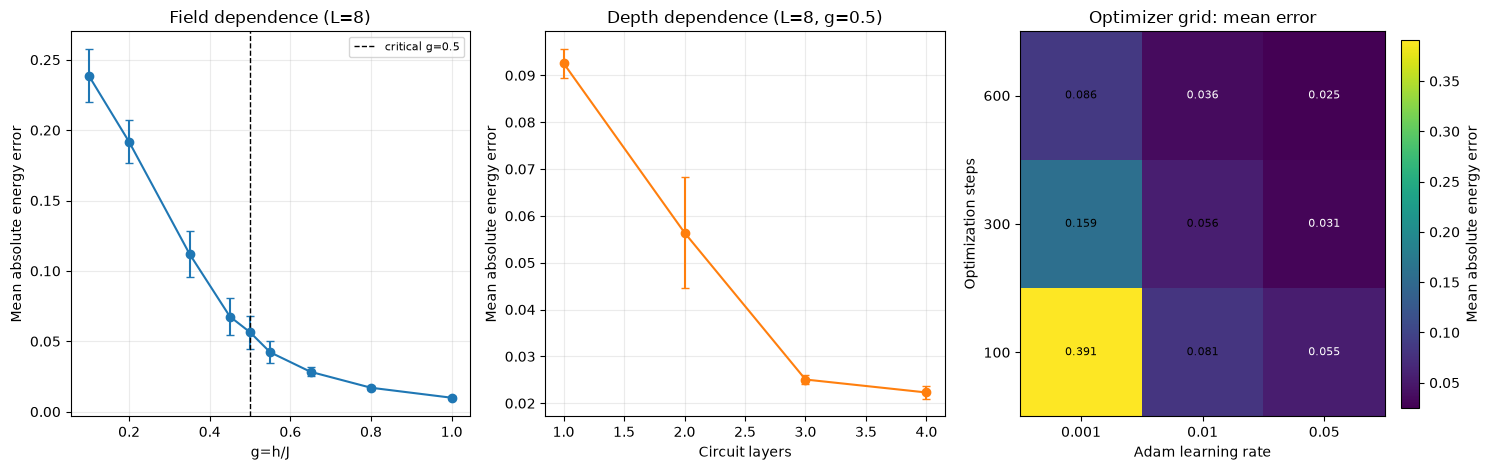

,g,mean,std,sweep,layers,steps,learning_rate
0,0.10,0.238767,0.019001,field,NaN,NaN,NaN
1,0.20,0.191706,0.015176,field,NaN,NaN,NaN
2,0.35,0.112050,0.016147,field,NaN,NaN,NaN
3,0.45,0.067579,0.012858,field,NaN,NaN,NaN
4,0.50,0.056415,0.011791,field,NaN,NaN,NaN
5,0.55,0.042180,0.007864,field,NaN,NaN,NaN
6,0.65,0.028327,0.003332,field,NaN,NaN,NaN
7,0.80,0.017004,0.001560,field,NaN,NaN,NaN
8,1.00,0.009904,0.000892,field,NaN,NaN,NaN
9,NaN,0.092600,0.003063,depth,1.0,NaN,NaN


In [6]:
if not vqe_done.empty:
    field = vqe_done[vqe_done.batch == "field_sweep"]
    depth = vqe_done[vqe_done.batch == "depth_sweep"]
    optimizer = vqe_done[vqe_done.batch == "optimizer_sweep"]

    field_summary = field.groupby("g").absolute_error.agg(["mean", "std"]).reset_index() if not field.empty else pd.DataFrame()
    depth_summary = depth.groupby("layers").absolute_error.agg(["mean", "std"]).reset_index() if not depth.empty else pd.DataFrame()
    optimizer_summary = (
        optimizer.groupby(["steps", "learning_rate"]).absolute_error.agg(["mean", "std"]).reset_index()
        if not optimizer.empty else pd.DataFrame()
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    if not field_summary.empty:
        axes[0].errorbar(field_summary.g, field_summary["mean"], yerr=field_summary["std"].fillna(0),
                         fmt="o-", capsize=3, color="tab:blue")
    axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1, label="critical g=0.5")
    axes[0].set(xlabel="g=h/J", ylabel="Mean absolute energy error", title="Field dependence (L=8)")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.25)

    if not depth_summary.empty:
        axes[1].errorbar(depth_summary.layers, depth_summary["mean"], yerr=depth_summary["std"].fillna(0),
                         fmt="o-", capsize=3, color="tab:orange")
    axes[1].set(xlabel="Circuit layers", ylabel="Mean absolute energy error", title="Depth dependence (L=8, g=0.5)")
    axes[1].grid(alpha=0.25)

    if not optimizer_summary.empty:
        heat = optimizer_summary.pivot(index="steps", columns="learning_rate", values="mean").sort_index()
        image = axes[2].imshow(heat.values, origin="lower", aspect="auto", cmap="viridis")
        axes[2].set_xticks(range(len(heat.columns)), [f"{x:g}" for x in heat.columns])
        axes[2].set_yticks(range(len(heat.index)), [str(x) for x in heat.index])
        axes[2].set(xlabel="Adam learning rate", ylabel="Optimization steps", title="Optimizer grid: mean error")
        median_val = np.nanmedian(heat.values)
        for iy in range(len(heat.index)):
            for ix in range(len(heat.columns)):
                val = heat.values[iy, ix]
                if pd.notna(val):
                    color = "white" if val < median_val else "black"
                    axes[2].text(ix, iy, f"{val:.3f}", ha="center", va="center", color=color, fontsize=8)
        fig.colorbar(image, ax=axes[2], label="Mean absolute energy error", fraction=0.046, pad=0.04)

    fig.tight_layout()
    fig.savefig(RESULTS / "vqe_parameter_sweeps.png", dpi=220, bbox_inches="tight")
    plt.show()

    summary_parts = []
    for frame, label in [(field_summary, "field"), (depth_summary, "depth"), (optimizer_summary, "optimizer")]:
        if not frame.empty:
            item = frame.copy()
            item["sweep"] = label
            summary_parts.append(item)
    if summary_parts:
        vqe_sweep_summary = pd.concat(summary_parts, ignore_index=True, sort=False)
        vqe_sweep_summary.to_csv(RESULTS / "vqe_parameter_sweep_summary.csv", index=False)
        display(vqe_sweep_summary)
else:
    print("No completed VQE rows found yet. Run 02_VQE_TFIM_Stress_Tests.ipynb first.")


 ## 6. Key quantitative metrics for `LAB_REPORT.md`



 Prints the exact measured summary statistics from all generated CSVs so `LAB_REPORT.md` can be populated with verified numbers.

In [7]:
def try_print_csv(name, description):
    path = RESULTS / name
    if path.exists():
        print(f"\n--- {description} ({name}) ---")
        print(pd.read_csv(path).to_string(index=False))

try_print_csv("dmrg_exact_crosscheck.csv", "DMRG vs Exact (L<=10)")
try_print_csv("dmrg_beta_fit.csv", "Order-parameter beta fit")
try_print_csv("dmrg_cft_central_charge_fit.csv", "CFT central charge fit")
try_print_csv("dmrg_eta_fit_windows.csv", "Critical correlation eta fits")
try_print_csv("vqe_size_seed_summary.csv", "VQE size/seed summary")


--- DMRG vs Exact (L<=10) (dmrg_exact_crosscheck.csv) ---
 L   g   E_exact    E_dmrg    abs_error  relative_error
 4 0.2 -0.816037 -0.816037 0.000000e+00    0.000000e+00
 6 0.2 -1.331906 -1.331906 2.898271e-09    2.176033e-09
 8 0.2 -1.851398 -1.851398 2.042336e-08    1.103132e-08
10 0.2 -2.371491 -2.371491 3.396630e-08    1.432276e-08
 4 0.5 -1.189693 -1.189693 1.110223e-15    9.332016e-16
 6 0.5 -1.824057 -1.824057 2.914011e-09    1.597544e-09
 8 0.5 -2.459488 -2.459488 3.577577e-08    1.454602e-08
10 0.5 -3.095372 -3.095372 2.905975e-09    9.388126e-10
 4 0.8 -1.718012 -1.718012 2.220446e-16    1.292451e-16
 6 0.8 -2.598242 -2.598242 2.654323e-09    1.021584e-09
 8 0.8 -3.478494 -3.478494 2.774672e-08    7.976647e-09
10 0.8 -4.358748 -4.358748 2.180235e-08    5.001974e-09

--- Order-parameter beta fit (dmrg_beta_fit.csv) ---
     window  beta_estimate   stderr  theory_beta  n_points
(0.4, 0.47)       6.627838 1.742738        0.125         3

--- CFT central charge fit (dmrg_cft_cen